# Clockwise playstyles: exploration

A workbench for deciding **whether** players fall into playstyles, **how many**, and **on what**, before anything gets
named or put on the dashboard. Nothing here is fixed: pick the side, the features and the number of groups in the
settings cell, re-run, compare.

**Data:** export JSON from the dashboard (**Data & settings → Export**) and set `DATA_PATH`. The default is the repo's
sample data, which is synthetic, so expect weak structure there.

1. **Data and fates:** how each player's games end (killed early, executed early, …, survived and won)
2. **Features:** the per-player rates, what shrinkage does to them, and how they correlate
3. **Choosing k:** every common criterion for k in `K_RANGE`, a no-structure baseline per k, and bootstrap stability per k
4. **Comparing candidate k's:** group profiles side by side, and how groups split as k grows
5. **Your chosen K:** profiles, members, per-player silhouette and stability, PCA map, dendrogram
6. **Nominations:** hound dogs / framers (no clustering involved)

In [1]:
# ---- Settings: change, then Run All (or re-run from the section you care about) ----
DATA_PATH = "../sample-data/botc-sample-games.json"   # your JSON export
SIDE = "good"            # "good", "evil" or "all"
MIN_GAMES = None         # None = 5 as good, 3 as evil, 5 for all
SHRINK = 5               # pretend average games added to each player's rates (0 = raw rates)

# Features to cluster on. Available (some only for good): killedEarly, execEarly, diedLater, execFinal, survived,
# winRate, noms, nomAccuracy*, enemyExecs, votes, voteAccuracy*   (* good only)
FEATURES_TO_USE = ["killedEarly", "execEarly", "execFinal", "survived", "winRate", "noms", "nomAccuracy", "enemyExecs", "voteAccuracy"]

K_RANGE = range(2, 9)    # k's to evaluate in section 3
K_COMPARE = [2, 3, 4]    # k's to put side by side in section 4
K = 3                    # your pick for section 5 (decide after looking at sections 3–4)

N_PERMUTATIONS = 100     # no-structure baseline (per k)
N_BOOTSTRAPS = 50        # stability (per k)
SEED = 7

In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, silhouette_samples, calinski_harabasz_score, davies_bouldin_score, adjusted_rand_score
from sklearn.mixture import GaussianMixture
from scipy.cluster.hierarchy import linkage, dendrogram

from playstyles import (load_games, seat_table, player_table, feature_matrix, features_for,
                        FATES, FATE_LABELS, FATE_COLORS, GROUP_COLORS, FEATURES, MIN_GAMES as DEFAULT_MIN)

warnings.filterwarnings("ignore", category=FutureWarning)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.25, "font.size": 10})
min_games = DEFAULT_MIN[SIDE] if MIN_GAMES is None else MIN_GAMES
side_word = {"good": "as good", "evil": "as evil", "all": "in all games"}[SIDE]
label = lambda f: FEATURES[f]["label"]

def km(M, k, n_init=20):
    return KMeans(k, n_init=n_init, random_state=SEED).fit(M)

games = load_games(DATA_PATH)
seats = seat_table(games)
ended = pd.to_datetime(pd.Series([g.get("endedAt") for g in games]), unit="ms")
print(f"{len(games)} games, {ended.min():%Y-%m-%d} to {ended.max():%Y-%m-%d}")
print(f"{seats['key'].nunique()} players, {len(seats)} seats (travellers left out)")
print(f"{seats['fate'].isna().sum()} seats with unknown fate (died before recording started)")
print(f"{(~seats.drop_duplicates('game')['tracked']).sum()} games joined part-way (left out of nomination stats)")

48 games, 2026-06-03 to 2026-10-18
30 players, 417 seats (travellers left out)
0 seats with unknown fate (died before recording started)
0 games joined part-way (left out of nomination stats)


## 1. Data and fates

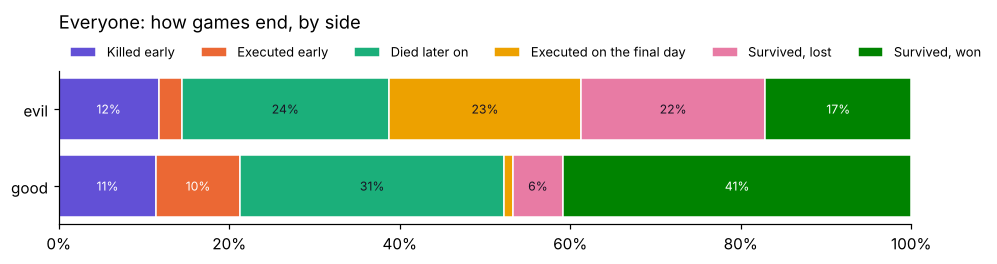

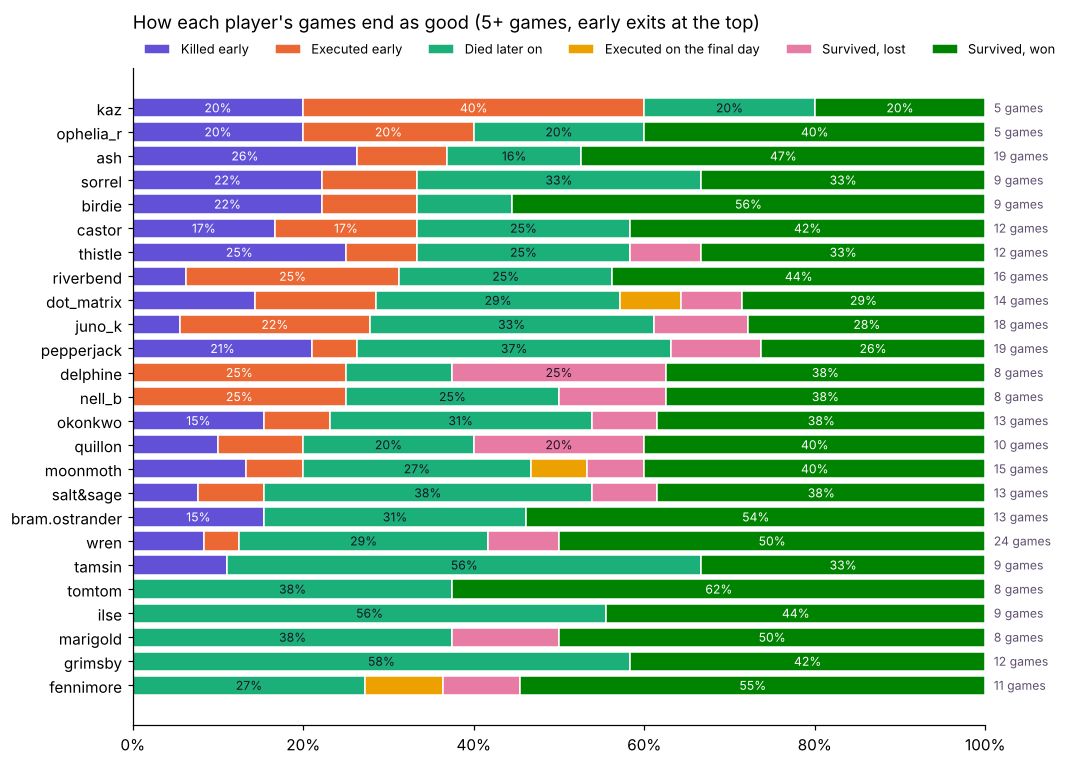

In [3]:
def fate_shares(df):
    known = df[df["fate"].notna()]
    return known["fate"].value_counts(normalize=True).reindex(FATES).fillna(0)

def stacked(ax, shares, label_min=0.07):
    left = np.zeros(len(shares))
    for f in FATES:
        ax.barh(shares.index, shares[f], left=left, color=FATE_COLORS[f], label=FATE_LABELS[f], edgecolor="white", linewidth=1)
        for i, v in enumerate(shares[f]):
            if v >= label_min:
                ax.text(left[i] + v / 2, i, f"{v:.0%}", ha="center", va="center", fontsize=8,
                        color="white" if f in ("killedEarly", "execEarly", "survivedWon") else "#1a1324")
        left += shares[f].values
    ax.set_xlim(0, 1); ax.grid(False); ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
    ax.legend(ncol=6, bbox_to_anchor=(0, 1.0, 1, 0.2), loc="lower left", frameon=False, fontsize=8.5)

overall = pd.DataFrame({s: fate_shares(seats[seats["side"] == s]) for s in ["good", "evil"]}).T
fig, ax = plt.subplots(figsize=(10, 1.8)); stacked(ax, overall, 0.05)
ax.set_title("Everyone: how games end, by side", loc="left", pad=28); plt.show()

side_seats = seats if SIDE == "all" else seats[seats["side"] == SIDE]
counts = side_seats.groupby("name")["game"].count()
keep = counts[counts >= min_games].index
shares = (side_seats[side_seats["name"].isin(keep) & side_seats["fate"].notna()]
          .groupby("name")["fate"].value_counts(normalize=True).unstack().reindex(columns=FATES).fillna(0))
shares = shares.loc[(shares["killedEarly"] + shares["execEarly"]).sort_values().index]
fig, ax = plt.subplots(figsize=(10, 0.27 * len(shares) + 1)); stacked(ax, shares, 0.15)
for i, n in enumerate(shares.index):
    ax.text(1.01, i, f"{counts[n]} games", va="center", fontsize=8, color="#5f5070")
ax.set_title(f"How each player's games end {side_word} ({min_games}+ games, early exits at the top)", loc="left", pad=26)
plt.show()

## 2. Features

Each rate is shrunk toward the table-wide rate: `(count + SHRINK × table rate) / (denominator + SHRINK)`, so a player
with a handful of games can't look extreme by luck. Then every feature is z-scored, so each counts equally in the
distance k-means uses.

In [4]:
players = player_table(seats, SIDE, shrink=SHRINK)
X, feats = feature_matrix(players, SIDE, min_games, FEATURES_TO_USE)
P = players.set_index("name").loc[X.index]
dropped = [f for f in FEATURES_TO_USE if f not in feats]
print(f"{len(X)} players with {min_games}+ games {side_word}")
print(f"clustering on {len(feats)} features: {', '.join(feats)}" + (f"  (dropped: {', '.join(dropped)})" if dropped else ""))
display(P[["games"] + [f"raw_{f}" for f in feats]].round(2).rename(columns=lambda c: c.replace("raw_", "")))

25 players with 5+ games as good
clustering on 9 features: killedEarly, execEarly, execFinal, survived, winRate, noms, nomAccuracy, enemyExecs, voteAccuracy


,games,killedEarly,execEarly,execFinal,survived,winRate,noms,nomAccuracy,enemyExecs,voteAccuracy
wren,24,0.08,0.04,0.00,0.58,0.71,0.79,0.58,0.21,0.40
pepperjack,19,0.21,0.05,0.00,0.37,0.58,0.42,0.38,0.05,0.22
ash,19,0.26,0.11,0.00,0.47,0.74,0.37,0.29,0.05,0.35
juno_k,18,0.06,0.22,0.00,0.39,0.50,0.39,0.29,0.06,0.30
riverbend,16,0.06,0.25,0.00,0.44,0.50,1.12,0.44,0.19,0.36
moonmoth,15,0.13,0.07,0.07,0.47,0.60,0.53,0.38,0.07,0.43
dot_matrix,14,0.14,0.14,0.07,0.36,0.64,0.57,0.50,0.00,0.38
salt&sage,13,0.08,0.08,0.00,0.46,0.54,0.54,0.29,0.15,0.36
okonkwo,13,0.15,0.08,0.00,0.46,0.62,0.85,0.45,0.08,0.38
bram.ostrander,13,0.15,0.00,0.00,0.54,0.54,0.69,0.44,0.08,0.16


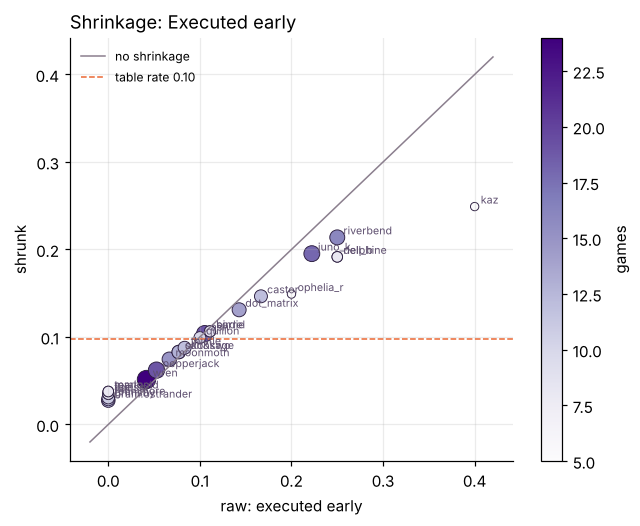

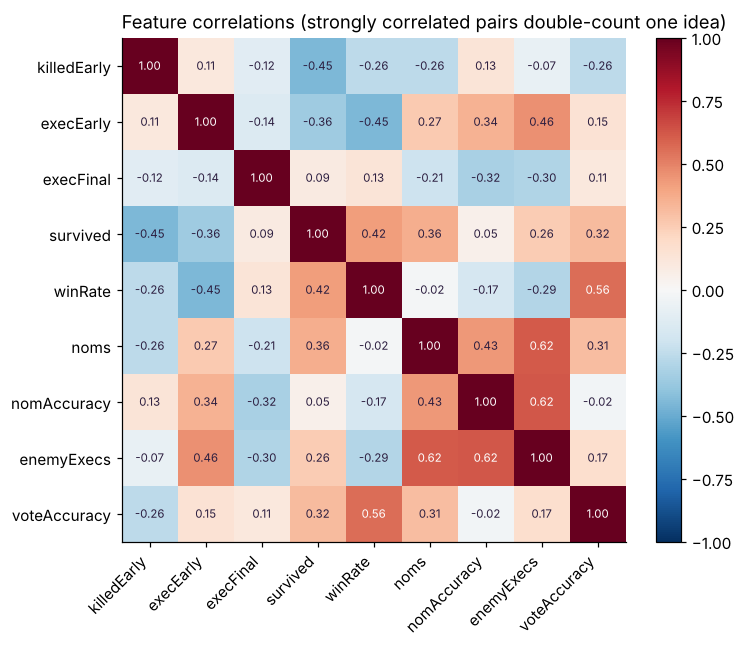

In [5]:
FEATURE_TO_SHOW = "execEarly"   # see shrinkage for any feature
f = FEATURE_TO_SHOW
table_rate = players[FEATURES[f]["num"]].sum() / players[FEATURES[f]["den"]].sum()
fig, ax = plt.subplots(figsize=(6.5, 5))
sc = ax.scatter(P[f"raw_{f}"], P[f"s_{f}"], s=P["games"] * 6, c=P["games"], cmap="Purples", edgecolor="#2b1d3f", linewidth=0.6)
lo = min(P[f"raw_{f}"].min(), P[f"s_{f}"].min()) - 0.02; hi = max(P[f"raw_{f}"].max(), P[f"s_{f}"].max()) + 0.02
ax.plot([lo, hi], [lo, hi], color="#8b7f8e", lw=1, label="no shrinkage")
ax.axhline(table_rate, color="#eb6834", ls="--", lw=1, label=f"table rate {table_rate:.2f}")
for n, r in P.iterrows():
    ax.annotate(n, (r[f"raw_{f}"], r[f"s_{f}"]), fontsize=7, xytext=(4, 2), textcoords="offset points", color="#5f5070")
ax.set_xlabel(f"raw: {label(f).lower()}"); ax.set_ylabel("shrunk"); ax.legend(frameon=False, fontsize=8)
plt.colorbar(sc, label="games"); ax.set_title(f"Shrinkage: {label(f)}", loc="left"); plt.show()

corr = X.corr()
fig, ax = plt.subplots(figsize=(0.62 * len(feats) + 1.5, 0.55 * len(feats) + 1))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(feats)), feats, rotation=45, ha="right"); ax.set_yticks(range(len(feats)), feats); ax.grid(False)
for i in range(len(feats)):
    for j in range(len(feats)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7.5, color="white" if abs(corr.iloc[i, j]) > 0.5 else "#2b1d3f")
plt.colorbar(im, fraction=0.046)
ax.set_title("Feature correlations (strongly correlated pairs double-count one idea)", loc="left"); plt.show()

## 3. Choosing k

The usual criteria, for every k in `K_RANGE`:

| Criterion | Better | Notes |
|---|---|---|
| Silhouette | higher | > 0.5 strong, 0.25–0.5 reasonable, < 0.25 weak |
| Inertia | look for the elbow | always falls as k grows |
| Calinski–Harabasz | higher | |
| Davies–Bouldin | lower | |
| GMM BIC | lower | model-based; penalises extra groups |
| Gap vs. no-structure | higher | real silhouette minus the median after shuffling each feature across players |
| Bootstrap stability | higher | median ARI when the games are resampled; > 0.75 stable, < 0.5 shaky |

Raw silhouette tends to creep up with k on small data (tiny groups fit easily), which is why the **gap over the
shuffled baseline** and **stability** are the ones to weigh most. A k that is both above the baseline band and stable is
a real candidate.

In [6]:
rng = np.random.default_rng(SEED)
ks = [k for k in K_RANGE if k < len(X)]

# Real-data criteria.
rows = []
for k in ks:
    m = km(X, k)
    gmm = GaussianMixture(k, covariance_type="diag", n_init=5, random_state=SEED).fit(X.values)
    rows.append(dict(k=k, silhouette=silhouette_score(X, m.labels_), inertia=m.inertia_,
                     calinski_harabasz=calinski_harabasz_score(X, m.labels_), davies_bouldin=davies_bouldin_score(X, m.labels_),
                     gmm_bic=gmm.bic(X.values), smallest_group=np.bincount(m.labels_).min()))
scores = pd.DataFrame(rows).set_index("k")

# No-structure baseline: shuffle each feature independently across players (keeps each feature's spread, breaks
# any link between them), cluster, record silhouette per k.
null = np.array([[silhouette_score(Z, km(Z, k, 5).labels_) for k in ks]
                 for Z in (np.column_stack([rng.permutation(X.values[:, j]) for j in range(X.shape[1])]) for _ in range(N_PERMUTATIONS))])
scores["null_median"] = np.median(null, axis=0)
scores["null_95th"] = np.percentile(null, 95, axis=0)
scores["gap"] = scores["silhouette"] - scores["null_median"]
scores["p_value"] = [(np.sum(null[:, i] >= scores.loc[k, "silhouette"]) + 1) / (len(null) + 1) for i, k in enumerate(ks)]

# Stability: resample games with replacement, rebuild the features, re-cluster, compare with the full-data grouping.
by_game = {g: df for g, df in seats.groupby("game")}
game_ids = list(by_game)
boot_X = []
for b in range(N_BOOTSTRAPS):
    pick = rng.choice(game_ids, size=len(game_ids), replace=True)
    boot = pd.concat([by_game[g].assign(game=f"{g}#{i}") for i, g in enumerate(pick)], ignore_index=True)
    Xb, _ = feature_matrix(player_table(boot, SIDE, shrink=SHRINK), SIDE, min_games, feats)
    boot_X.append(Xb.reindex(columns=feats).fillna(0))

def stability(k):
    ref = pd.Series(km(X, k).labels_, index=X.index)
    out = []
    for Xb in boot_X:
        common = Xb.index.intersection(X.index)
        if len(common) > 2 * k:
            lab = pd.Series(km(Xb, k, 10).labels_, index=Xb.index)[common]
            out.append(adjusted_rand_score(ref[common], lab))
    return np.array(out)

stab = {k: stability(k) for k in ks}
scores["stability_ARI"] = [np.median(stab[k]) for k in ks]
display(scores.round(3))

,silhouette,inertia,calinski_harabasz,davies_bouldin,gmm_bic,smallest_group,null_median,null_95th,gap,p_value,stability_ARI
k,,,,,,,,,,,
2,0.154,177.363,6.177,1.854,604.472,12,0.134,0.232,0.021,0.287,0.062
3,0.157,144.952,6.075,1.540,635.528,5,0.129,0.176,0.028,0.198,0.176
4,0.133,125.946,5.505,1.499,511.298,4,0.132,0.172,0.001,0.485,0.162
5,0.150,111.338,5.104,1.397,496.232,3,0.137,0.177,0.014,0.267,0.158
6,0.162,97.605,4.960,1.153,474.500,1,0.136,0.187,0.026,0.228,0.132
7,0.181,81.853,5.247,1.117,391.168,1,0.137,0.185,0.044,0.089,0.145
8,0.202,70.481,5.324,0.944,340.740,1,0.142,0.190,0.060,0.030,0.122


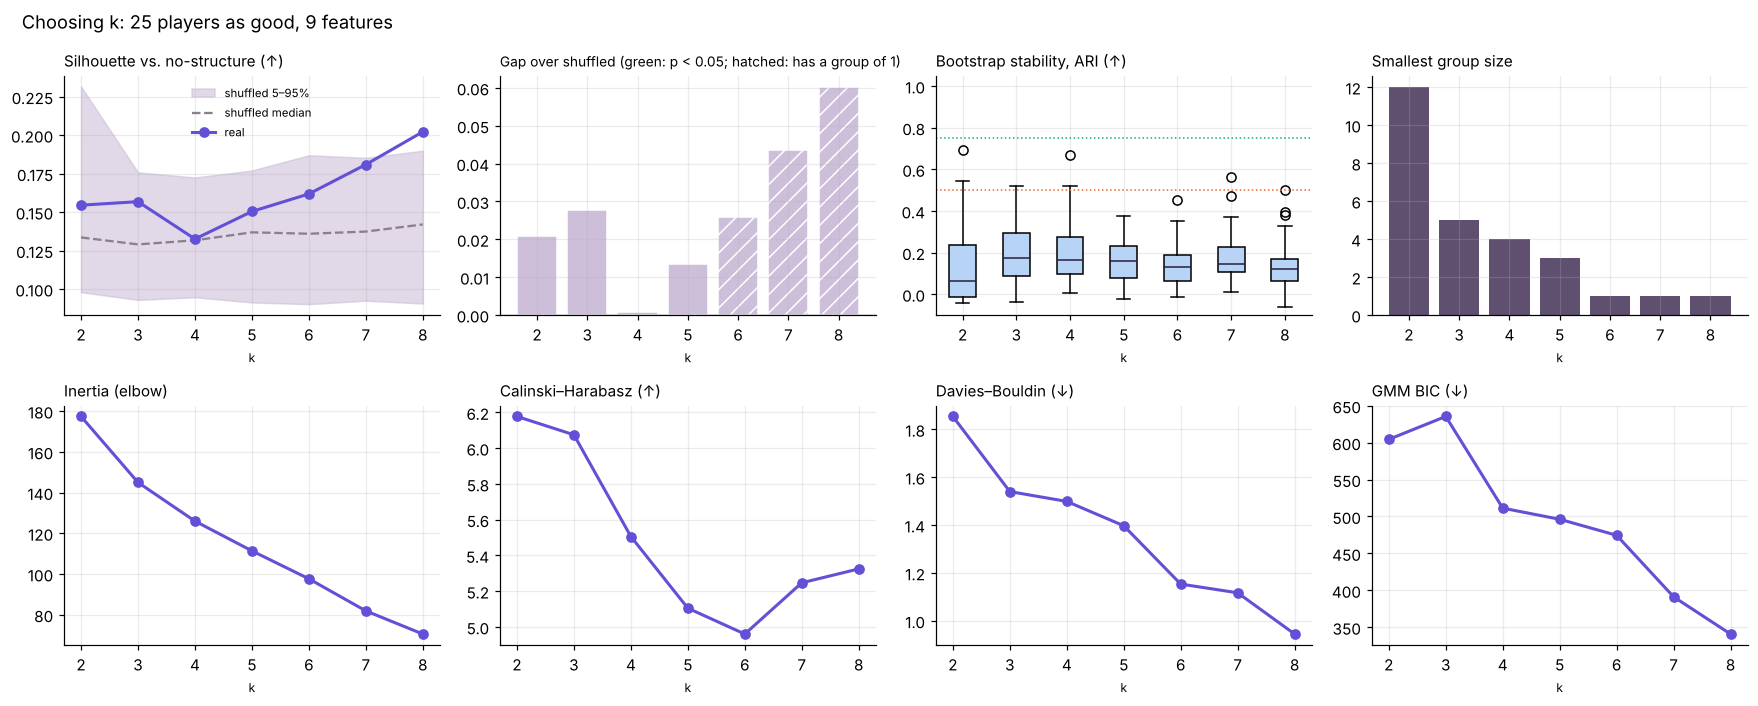

In [7]:
fig, axes = plt.subplots(2, 4, figsize=(16, 6.5))
a = axes[0, 0]
a.fill_between(ks, np.percentile(null, 5, axis=0), np.percentile(null, 95, axis=0), color="#cdbfda", alpha=0.6, label="shuffled 5–95%")
a.plot(ks, scores["null_median"], color="#8b7f8e", ls="--", label="shuffled median")
a.plot(ks, scores["silhouette"], marker="o", color="#6250d6", lw=2, label="real")
a.set_title("Silhouette vs. no-structure (↑)", loc="left", fontsize=10); a.legend(frameon=False, fontsize=7.5)
# Green only when beating the shuffles (p < 0.05) without a group of one; a lone outlier "group" inflates silhouette.
ok = (scores["p_value"] < 0.05) & (scores["smallest_group"] >= 2)
axes[0, 1].bar(ks, scores["gap"], color=["#1baf7a" if o else "#cdbfda" for o in ok],
               hatch=["//" if s < 2 else "" for s in scores["smallest_group"]], edgecolor="white")
axes[0, 1].axhline(0, color="#2b1d3f", lw=0.8)
axes[0, 1].set_title("Gap over shuffled (green: p < 0.05; hatched: has a group of 1)", loc="left", fontsize=9)
a = axes[0, 2]
a.boxplot([stab[k] for k in ks], positions=ks, widths=0.5, patch_artist=True, boxprops=dict(facecolor="#b7d3f6"), medianprops=dict(color="#2b1d3f"))
a.axhline(0.75, color="#1baf7a", ls=":", lw=1); a.axhline(0.5, color="#eb6834", ls=":", lw=1); a.set_ylim(-0.1, 1.05)
a.set_title("Bootstrap stability, ARI (↑)", loc="left", fontsize=10)
axes[0, 3].bar(ks, scores["smallest_group"], color="#5f5070"); axes[0, 3].set_title("Smallest group size", loc="left", fontsize=10)
for a, col, t in zip(axes[1], ["inertia", "calinski_harabasz", "davies_bouldin", "gmm_bic"], ["Inertia (elbow)", "Calinski–Harabasz (↑)", "Davies–Bouldin (↓)", "GMM BIC (↓)"]):
    a.plot(ks, scores[col], marker="o", color="#6250d6", lw=2); a.set_title(t, loc="left", fontsize=10)
for a in axes.flat:
    a.set_xticks(ks); a.set_xlabel("k", fontsize=8)
plt.suptitle(f"Choosing k: {len(X)} players {side_word}, {len(feats)} features", x=0.01, ha="left", fontsize=12)
plt.tight_layout(); plt.show()

## 4. Comparing candidate k's

Group profiles for each k in `K_COMPARE` (each cell is the group's average in z units: how many spreads above or below
the average player). Below that, a cross-tab of how the groups at one k split into the next, which shows whether a
bigger k finds a genuinely new kind of player or just shaves a few people off an existing group.

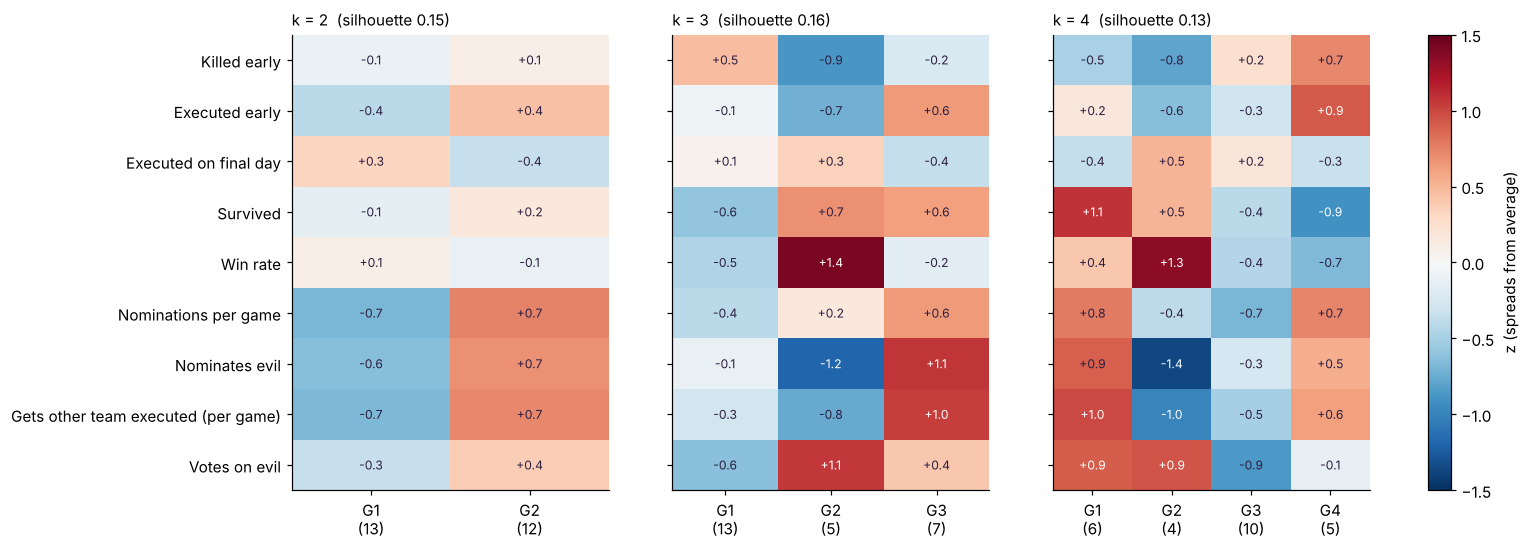

How the k=2 groups split at k=3:


k=3,G1,G2,G3
k=2,,,
G1,9,4,0
G2,4,1,7


How the k=3 groups split at k=4:


k=4,G1,G2,G3,G4
k=3,,,,
G1,0,0,10,3
G2,1,4,0,0
G3,5,0,0,2


In [8]:
fits = {k: km(X, k) for k in K_COMPARE}
lim = max(1.5, max(np.abs(f.cluster_centers_).max() for f in fits.values()))
fig, axes = plt.subplots(1, len(K_COMPARE), figsize=(4.2 * len(K_COMPARE) + 1, 0.42 * len(feats) + 1.6), sharey=True)
for a, k in zip(np.atleast_1d(axes), K_COMPARE):
    C = pd.DataFrame(fits[k].cluster_centers_, columns=feats).T
    sizes = np.bincount(fits[k].labels_, minlength=k)
    im = a.imshow(C, cmap="RdBu_r", vmin=-lim, vmax=lim, aspect="auto")
    a.set_xticks(range(k), [f"G{i + 1}\n({sizes[i]})" for i in range(k)]); a.grid(False)
    a.set_yticks(range(len(feats)), [label(f) for f in feats])
    for i in range(len(feats)):
        for j in range(k):
            a.text(j, i, f"{C.iloc[i, j]:+.1f}", ha="center", va="center", fontsize=8, color="white" if abs(C.iloc[i, j]) > lim * 0.6 else "#2b1d3f")
    a.set_title(f"k = {k}  (silhouette {silhouette_score(X, fits[k].labels_):.2f})", loc="left", fontsize=10)
plt.colorbar(im, ax=axes, fraction=0.02, label="z (spreads from average)"); plt.show()

for a_k, b_k in zip(K_COMPARE, K_COMPARE[1:]):
    ct = pd.crosstab(pd.Series(fits[a_k].labels_ + 1, name=f"k={a_k}").map(lambda g: f"G{g}"),
                     pd.Series(fits[b_k].labels_ + 1, name=f"k={b_k}").map(lambda g: f"G{g}"))
    print(f"How the k={a_k} groups split at k={b_k}:"); display(ct)

## 5. Your chosen K

Set `K` in the settings cell. Groups are just numbered: the table of standout traits is there to help you decide what
(if anything) to call them.

In [9]:
fit = km(X, K)
lab = pd.Series(fit.labels_, index=X.index)
C = pd.DataFrame(fit.cluster_centers_, columns=feats, index=[f"G{i + 1}" for i in range(K)])
sil = pd.Series(silhouette_samples(X, fit.labels_), index=X.index)
print(f"k = {K}: silhouette {sil.mean():.3f}, stability ARI " + (f"{scores.loc[K, 'stability_ARI']:.2f}" if K in scores.index else "n/a (K not in K_RANGE)"))

# Standout traits per group: largest |z|, with the group's pooled raw rate next to everyone's.
def pooled(names, f):
    d = FEATURES[f]; sub = P.loc[names]
    return sub[d["num"]].sum() / max(sub[d["den"]].sum(), 1)
rows = []
for g in range(K):
    members = lab.index[lab == g]
    for f in C.columns[np.argsort(-np.abs(C.iloc[g].values))][:4]:
        rows.append(dict(group=f"G{g + 1}", size=len(members), feature=label(f), z=C.iloc[g][f],
                         group_rate=pooled(members, f), everyone=pooled(X.index, f)))
display(pd.DataFrame(rows).set_index(["group", "size"]).round(2))
for g in range(K):
    print(f"G{g + 1} ({(lab == g).sum()}): {', '.join(lab.index[lab == g])}")

k = 3: silhouette 0.157, stability ARI 0.18


feature     z  group_rate  everyone
group size                                                                 
G1    13                          Votes on evil -0.63        0.34      0.40
      13                               Survived -0.59        0.42      0.47
      13                           Killed early  0.46        0.15      0.12
      13                               Win rate -0.45        0.61      0.65
G2    5                                Win rate  1.42        0.82      0.65
      5                          Nominates evil -1.19        0.25      0.44
      5                           Votes on evil  1.07        0.51      0.40
      5                            Killed early -0.87        0.04      0.12
G3    7                          Nominates evil  1.07        0.57      0.44
      7     Gets other team executed (per game)  1.04        0.21      0.10
      7                          Executed early  0.64        0.15      0.10
      7                    Nominations per game  0.64        0.88      0.68

G1 (13): pepperjack, ash, juno_k, moonmoth, dot_matrix, salt&sage, okonkwo, bram.ostrander, thistle, tamsin, sorrel, ilse, kaz
G2 (5): grimsby, castor, fennimore, marigold, tomtom
G3 (7): wren, riverbend, quillon, birdie, delphine, nell_b, ophelia_r


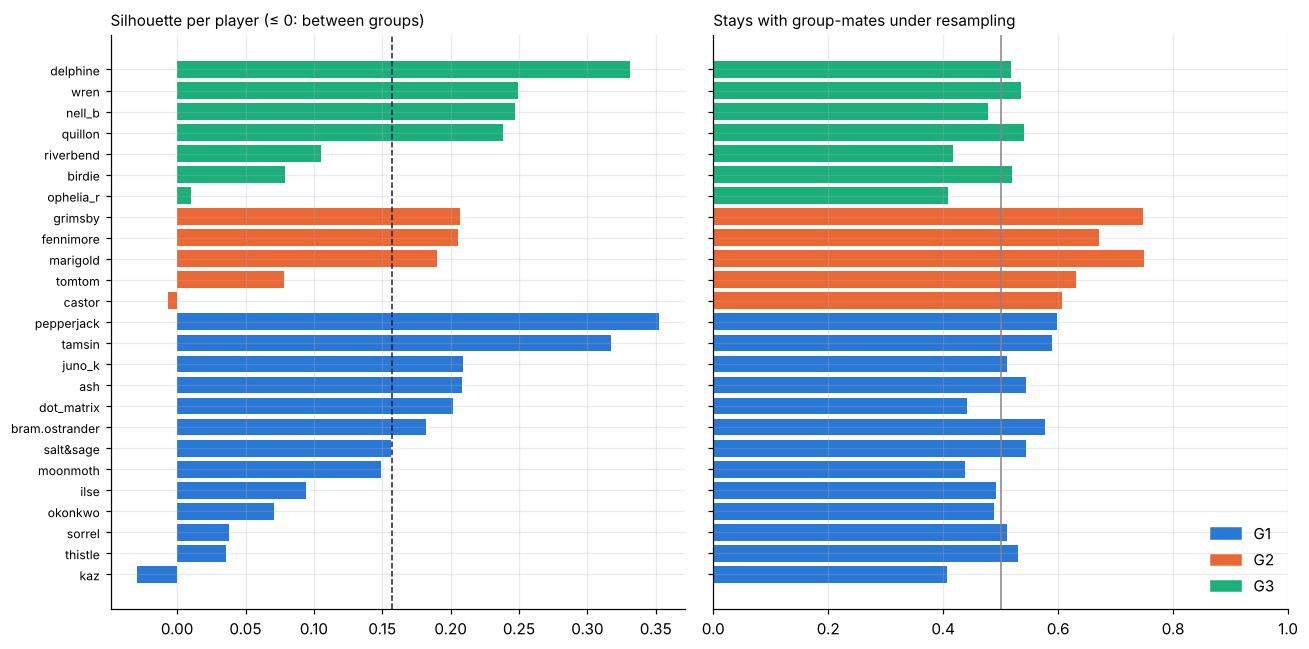

In [10]:
# Per player: silhouette (how well they fit their group) and bootstrap co-assignment (how often they stay with their
# group-mates when the games are resampled).
together = pd.DataFrame(0.0, index=X.index, columns=X.index); seen = together.copy()
for Xb in boot_X:
    common = Xb.index.intersection(X.index)
    if len(common) > 2 * K:
        lb = pd.Series(km(Xb, K, 10).labels_, index=Xb.index)[common].values
        together.loc[common, common] += (lb[:, None] == lb[None, :]); seen.loc[common, common] += 1
co = together / seen.replace(0, np.nan)
stay = pd.Series({n: co.loc[n, lab.index[(lab == lab[n]) & (lab.index != n)]].mean() for n in X.index})

order = sorted(X.index, key=lambda n: (lab[n], sil[n]))
colors = [GROUP_COLORS[lab[n] % len(GROUP_COLORS)] for n in order]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, max(3, 0.24 * len(X))), sharey=True)
a1.barh(order, sil[order], color=colors); a1.axvline(sil.mean(), color="#2b1d3f", ls="--", lw=1)
a1.set_title("Silhouette per player (≤ 0: between groups)", loc="left", fontsize=10)
a2.barh(order, stay[order], color=colors); a2.set_xlim(0, 1); a2.axvline(0.5, color="#8b7f8e", lw=1)
a2.set_title("Stays with group-mates under resampling", loc="left", fontsize=10)
a1.tick_params(axis="y", labelsize=8)
handles = [plt.Rectangle((0, 0), 1, 1, color=GROUP_COLORS[g % len(GROUP_COLORS)]) for g in range(K)]
a2.legend(handles, [f"G{g + 1}" for g in range(K)], frameon=False, loc="lower right")
plt.tight_layout(); plt.show()

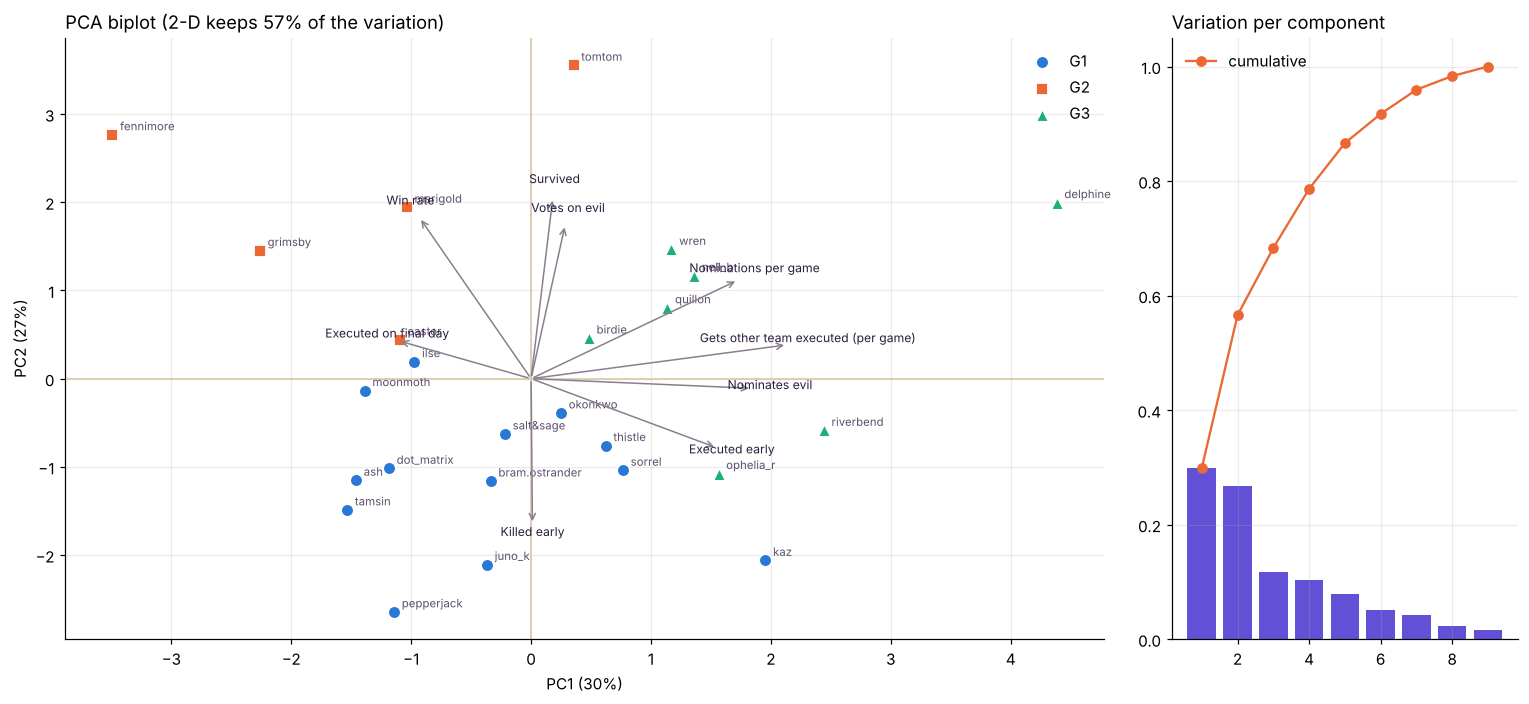

Loadings (what each axis is made of):


,PC1,PC2,PC3
Killed early,0.00,-0.42,-0.03
Executed early,0.39,-0.20,0.59
Executed on final day,-0.28,0.11,0.47
Survived,0.05,0.52,-0.33
Win rate,-0.24,0.46,-0.00
Nominations per game,0.44,0.28,-0.02
Nominates evil,0.47,-0.03,-0.20
Gets other team executed (per game),0.54,0.10,-0.04
Votes on evil,0.07,0.44,0.52


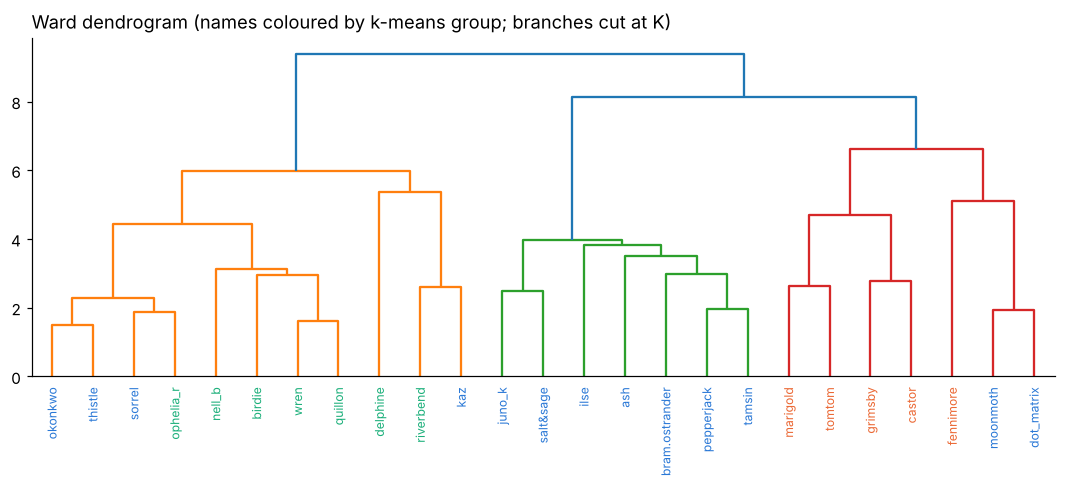

In [11]:
pca = PCA().fit(X)
xy = pca.transform(X)[:, :2]
ev = pca.explained_variance_ratio_
fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 6.5), gridspec_kw={"width_ratios": [3, 1]})
markers = ["o", "s", "^", "D", "v", "P", "X", "*"]
for g in range(K):
    m = lab.values == g
    a1.scatter(xy[m, 0], xy[m, 1], s=70, marker=markers[g % 8], color=GROUP_COLORS[g % len(GROUP_COLORS)], edgecolor="white", linewidth=1.2, label=f"G{g + 1}", zorder=3)
for (x, y), n in zip(xy, X.index):
    a1.annotate(n, (x, y), fontsize=7.5, xytext=(5, 3), textcoords="offset points", color="#5f5070")
scale = np.abs(xy).max() * 0.9
for j, f in enumerate(feats):
    lx, ly = pca.components_[0, j] * scale, pca.components_[1, j] * scale
    a1.annotate("", (lx, ly), (0, 0), arrowprops=dict(arrowstyle="->", color="#8b7f8e", lw=1))
    a1.text(lx * 1.08, ly * 1.08, label(f), fontsize=8, color="#2b1d3f", ha="center")
a1.axhline(0, color="#d5c4a4", lw=1); a1.axvline(0, color="#d5c4a4", lw=1)
a1.set_xlabel(f"PC1 ({ev[0]:.0%})"); a1.set_ylabel(f"PC2 ({ev[1]:.0%})"); a1.legend(frameon=False)
a1.set_title(f"PCA biplot (2-D keeps {ev[:2].sum():.0%} of the variation)", loc="left")
a2.bar(range(1, len(ev) + 1), ev, color="#6250d6"); a2.plot(range(1, len(ev) + 1), np.cumsum(ev), marker="o", color="#eb6834", label="cumulative")
a2.set_title("Variation per component", loc="left"); a2.legend(frameon=False)
plt.tight_layout(); plt.show()

loadings = pd.DataFrame(pca.components_[:3].T, index=[label(f) for f in feats], columns=["PC1", "PC2", "PC3"])
print("Loadings (what each axis is made of):"); display(loadings.round(2))

Z = linkage(X.values, method="ward")
fig, ax = plt.subplots(figsize=(12, 4))
dendrogram(Z, labels=list(X.index), leaf_rotation=90, leaf_font_size=8, color_threshold=Z[-(K - 1), 2], ax=ax)
for t in ax.get_xticklabels():
    t.set_color(GROUP_COLORS[lab[t.get_text()] % len(GROUP_COLORS)])
ax.grid(False); ax.set_title("Ward dendrogram (names coloured by k-means group; branches cut at K)", loc="left"); plt.show()

## 6. Nominations: hound dogs / framers

In [12]:
tr = P[P["tracked"] > 0]
hound = pd.DataFrame({
    "games": tr["tracked"],
    "noms_per_game": tr["noms"] / tr["tracked"],
    "noms_on_evil": tr["nomsOnEvil"] / tr["noms"].replace(0, np.nan),
    "other_team_executed": tr["enemyExecs"],
    "per_game": tr["enemyExecs"] / tr["tracked"],
    "per_game_shrunk": tr["s_enemyExecs"],
    "votes_on_evil": tr["votesOnEvil"] / tr["votes"].replace(0, np.nan),
}).sort_values("per_game_shrunk", ascending=False)
if SIDE != "good":
    hound = hound.drop(columns=["noms_on_evil", "votes_on_evil"])
display(hound.round(2))

,games,noms_per_game,noms_on_evil,other_team_executed,per_game,per_game_shrunk,votes_on_evil
delphine,8,1.25,0.70,4,0.50,0.35,0.50
wren,24,0.79,0.58,5,0.21,0.19,0.40
sorrel,9,0.67,0.50,2,0.22,0.18,0.42
riverbend,16,1.12,0.44,3,0.19,0.17,0.36
quillon,10,0.80,0.50,2,0.20,0.17,0.44
ophelia_r,5,0.80,0.75,1,0.20,0.15,0.33
kaz,5,1.00,0.40,1,0.20,0.15,0.46
salt&sage,13,0.54,0.29,2,0.15,0.14,0.36
nell_b,8,0.75,0.67,1,0.12,0.11,0.53
tomtom,8,1.38,0.36,1,0.12,0.11,0.58
